<a href="https://colab.research.google.com/github/Artahko/lab2_Zahariuk_Kravchenko_Yakymashchenko/blob/main/lab2_Zahariuk_Kravchenko_Yakymashchenko.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Probability and Statistics Lab 2: random variables, and limit theorems

## General comments and instructions

-   The report must be prepared as *jupyter notebook along with compiled PDF*.
-   For each task, include
    -   the statistics obtained (like sample mean or anything else you use to complete the task) as well as histograms etc to illustrate your findings;
    -   justification of your solution (e.g. refer to the corresponding theorems from probability theory); whenever applicable, provide LaTeX formulas and derivations.
    -   conclusions (e.g. how reliable your answer is, does it agree with common sense expectations etc.).
-   Not complying with these instructions may result in point deduction.


### Work breakdown:

- **Mariia-Daryna Zahariuk**: Task 1 (Hamming codes) & Task 4.1 (Expectation properties & transformations)
- **Daria Kravchenko**: Task 2 (Particle decay) & Task 4.2 (a, b) (Coin toss & Binomial distribution)
- **Artem Yakymashchenko**: Task 3 (Geiger counter) & Task 4.2 (c, d) (Game fairness, variance & sample size)

A **team id number** referred to in tasks is the **two-digit** ordinal number of your team on the list. We keep it for reproducible calculations.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats

team_id: int = 18

random.seed(team_id)
np.random.seed(team_id)

## Task 1. Hamming codes


In this task, we discuss the $[7, 4]$ Hamming code and investigate its reliability. That coding system can correct single errors in the transmission of 4-bit messages and proceeds as follows:

(a) given a message $m = (a_1a_2a_3a_4)$, we first encode it to a 7-bit codeword $c = mG = (x_1x_2x_3x_4x_5x_6x_7)$, where $G$ is a $4 \times 7$ generator matrix

(b) the codeword $c$ is transmitted, and $r$ is the received message

(c) $r$ is checked for errors by calculating the syndrome vector $z := rH$, for a $7 \times 3$ parity-check matrix $H$

(d) if a single error has occurred in $r$, then the binary $z = (z_1z_2z_3)$ identifies the wrong bit no. $z_1 + 2z_2 + 4z_3$; thus $(000)$ shows there was no error (or more than one), while $(110)$ means the third bit (or more than one) got corrupted

(e) if the error was identified, then we flip the corresponding bit in $r$ to get the corrected $r^* = (r_1^*r_2^*r_3^*r_4^*r_5^*r_6^*r_7^*)$; the decoded message is then $m^* := (r_3^*r_5^*r_6^*r_7^*)$.

The generator matrix $G$ and the parity-check matrix $H$ are given by

$$
G := \begin{pmatrix}
1 & 1 & 1 & 0 & 0 & 0 & 0 \\
1 & 0 & 0 & 1 & 1 & 0 & 0 \\
0 & 1 & 0 & 1 & 0 & 1 & 0 \\
1 & 1 & 0 & 1 & 0 & 0 & 1
\end{pmatrix},
\qquad
H^\top := \begin{pmatrix}
1 & 0 & 1 & 0 & 1 & 0 & 1 \\
0 & 1 & 1 & 0 & 0 & 1 & 1 \\
0 & 0 & 0 & 1 & 1 & 1 & 1
\end{pmatrix}
$$
*$GH$ must equal a zero-matrix modulo 2.*


Assume that each bit in the transmission $c \mapsto r$ gets corrupted independently of the others with probability $p = (2 + \frac{\text{team-id-number}}{4})/100$. Your task:

1. Simulate the encoding-transmission-decoding process $N$ times and find the estimate $\hat p$ of the probability $p^*$ of correct transmission of a single message $m$. Comment why, for large $N$, $\hat p$ is expected to be close to $p^*$.
2. By estimating the standard deviation of the corresponding indicator of success by the sample standard deviation and using the CLT, find the half-length $\varepsilon$ of the confidence interval $(\hat p - \varepsilon, \hat p + \varepsilon)$, which contains the true value $p^*$ with probability at least $0.95$. What choice of $N$ guarantees that $\varepsilon \le 0.03$?
3. Draw the histogram of the number $k = 0, 1, 2, 3, 4$ of errors in $m^*$ while transmitting a 4-digit binary message. Do you think the random variable that counts the number of wrong bits in a decoded message has one of the known distributions? Justify your answer.


### 1: simulation and analysis of [7, 4] Hamming Code

#### theoretical formulations:
1. **Encoding:** For a 4-bit message vector $m \in \mathbb{F}_2^4$, the encoded 7-bit codeword is $c = m G \pmod 2$, where $G$ is the $4 \times 7$ generator matrix.
2. **Transmission & Noise:** Each bit of $c$ is corrupted independently with probability $p = \left(2 + \frac{\text{team\_id}}{4}\right)/100 = 0.065$ (team_id = 18). The received vector is $r = c \oplus e$.
3. **Syndrome & Error Correction:** The syndrome vector is $z = r H \pmod 2$. If $z = (0,0,0)$, no single error occurred. If $z \ne (0,0,0)$, the binary value $z_1 + 2z_2 + 4z_3$ pinpoints the exact 1-based index of the flipped bit, which is corrected to produce $r^*$.
4. **Decoded Message:** The original message is extracted as $m^* = (r_3^*, r_5^*, r_6^*, r_7^*)$.
5. **Law of Large Numbers & CLT:**
   - By the Law of Large Numbers (LLN), the empirical frequency $\hat{p} = \frac{1}{N} \sum_{i=1}^N \mathbf{1}_{\{m_i = m_i^*\}}$ converges in probability to the true success probability $p^*$.
   - By the Central Limit Theorem (CLT), the sample error $\hat{p} - p^*$ is asymptotically normal $\mathcal{N}\left(0, \frac{p^*(1-p^*)}{N}\right)$. The $95\%$ confidence interval margin of error is $\varepsilon = z_{0.975} \frac{\hat{\sigma}}{\sqrt{N}} \approx 1.96 \sqrt{\frac{\hat{p}(1-\hat{p})}{N}}$.

Task 1.1
Bit corruption probability p: 0.0650
Estimated correct transmission probability p_hat: 0.93058

Task 1.2
95% Confidence Interval Half-length epsilon: 0.00158
95% Confidence Interval for p*: [0.92900, 0.93216]
Required N to guarantee epsilon <= 0.03: N >= 276

Task 1.3
Messages with k=0 errors: 93058 (93.06%)
Messages with k=1 errors: 2741 (2.74%)
Messages with k=2 errors: 3033 (3.03%)
Messages with k=3 errors: 1168 (1.17%)
Messages with k=4 errors: 0 (0.00%)


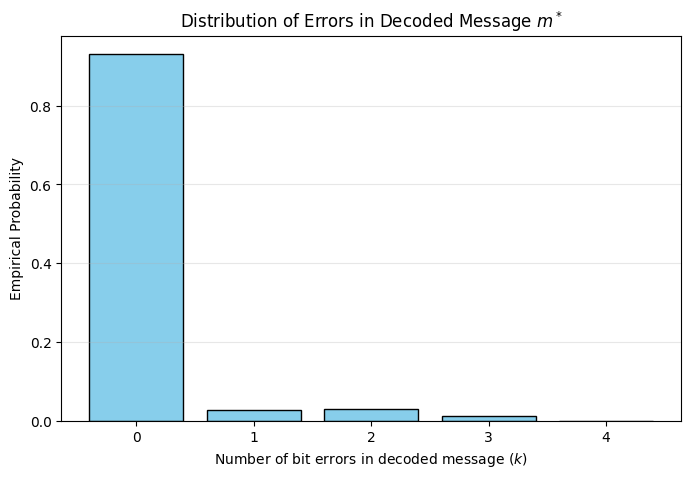

In [2]:
# Task 1: Hamming [7, 4] Code Simulation and Statistical Analysis

# Parameter setup
p_bit = (2 + team_id / 4) / 100  # Bit error rate p = 0.065 for our team
N = 100000                        # Number of simulations

# Matrices over F2
G = np.array([
    [1, 1, 1, 0, 0, 0, 0],
    [1, 0, 0, 1, 1, 0, 0],
    [0, 1, 0, 1, 0, 1, 0],
    [1, 1, 0, 1, 0, 0, 1]
], dtype=int)

# Parity-check matrix H^T (7 x 3)
H_T = np.array([
    [1, 0, 0],
    [0, 1, 0],
    [1, 1, 0],
    [0, 0, 1],
    [1, 0, 1],
    [0, 1, 1],
    [1, 1, 1]
], dtype=int)

# 1. Simulate N transmissions
np.random.seed(team_id)

# Generate random 4-bit messages m
m = np.random.randint(0, 2, size=(N, 4))

# Encode: c = m @ G (mod 2)
c = (m @ G) % 2

# Transmission noise: generate binary error matrix with probability p_bit
noise = (np.random.random(size=(N, 7)) < p_bit).astype(int)
r = (c + noise) % 2

# Compute Syndrome: z = r @ H_T (mod 2)
z = (r @ H_T) % 2

# Convert binary syndrome (z1, z2, z3) to 1-based error bit position: z1 + 2*z2 + 4*z3
error_pos = z[:, 0] + 2 * z[:, 1] + 4 * z[:, 2]

# Correct errors
r_corrected = r.copy()
for i in range(N):
    pos = error_pos[i]
    if pos > 0:
        r_corrected[i, pos - 1] ^= 1  # Flip bit at corresponding position

# Extract decoded message m* = (r3*, r5*, r6*, r7*) -> zero-indexed indices: 2, 4, 5, 6
m_decoded = r_corrected[:, [2, 4, 5, 6]]

# Calculate errors per message
bit_errors_decoded = np.sum(m != m_decoded, axis=1)
correct_transmissions = (bit_errors_decoded == 0)

# Estimate p* (probability of correct message transmission)
p_hat = np.mean(correct_transmissions)

print(f"Task 1.1")
print(f"Bit corruption probability p: {p_bit:.4f}")
print(f"Estimated correct transmission probability p_hat: {p_hat:.5f}")

# 2. Confidence Interval & Choice of N
sigma_hat = np.sqrt(p_hat * (1 - p_hat))
z_alpha = scipy.stats.norm.ppf(0.975)  # 1.95996
epsilon = z_alpha * sigma_hat / np.sqrt(N)

# N required for epsilon <= 0.03
N_req = int(np.ceil((z_alpha * sigma_hat / 0.03) ** 2))

print(f"\nTask 1.2")
print(f"95% Confidence Interval Half-length epsilon: {epsilon:.5f}")
print(f"95% Confidence Interval for p*: [{p_hat - epsilon:.5f}, {p_hat + epsilon:.5f}]")
print(f"Required N to guarantee epsilon <= 0.03: N >= {N_req}")

# 3. Histogram and Distribution Analysis
print(f"\nTask 1.3")
error_counts = np.bincount(bit_errors_decoded, minlength=5)
for k in range(5):
    print(f"Messages with k={k} errors: {error_counts[k]} ({error_counts[k]/N*100:.2f}%)")

plt.figure(figsize=(8, 5))
bins = np.arange(-0.5, 5.5, 1)
plt.hist(bit_errors_decoded, bins=bins, rwidth=0.8, color='skyblue', edgecolor='black', density=True)
plt.xticks(range(5), labels=['0', '1', '2', '3', '4'])
plt.xlabel("Number of bit errors in decoded message ($k$)")
plt.ylabel("Empirical Probability")
plt.title("Distribution of Errors in Decoded Message $m^*$")
plt.grid(axis='y', alpha=0.3)
plt.show()


#### 1.3: Conclusion on Error Distribution:
The random variable counting the number of wrong bits in the decoded message $m^*$ **does not follow a standard Binomial distribution $\text{Binom}(4, p_{bit})$**.

* **Reason:** The Hamming code actively corrects all single-bit transmission errors across the 7-bit codeword. Therefore:
  - If $0$ errors occur in transmission, 0 errors remain in $m^*$.
  - If $1$ error occurs in transmission, the syndrome locates and corrects it, resulting in 0 errors in $m^*$.
  - If $2$ or more errors occur in transmission, the syndrome calculation misidentifies the position, causing an incorrect bit flip and generating multiple errors in $m^*$.
* Because bit errors in $m^*$ are strongly dependent due to the deterministic decoding scheme, the resulting distribution is a complex mixture rather than independent Bernoulli trials.

## Task 2. Particle decay

In this task, we discuss a real-life process that is well modelled by a Poisson distribution. As you remember, a Poisson random variable describes occurrences of rare events, i.e., counts the number of successes in a large number of independent random experiments. One of the typical examples is the radioactive decay process.

Consider a sample of radioactive element of mass $m$, which has a large half-life period $T$; it is vitally important to know the probability that during a one second period, the number of nuclei decays will not exceed some critical level $k$. This probability can easily be estimated using the fact that, given the decay constant $\lambda$ of the element (i.e., the probability that a given nucleus decays within one second) and the number $N$ of atoms in the sample, the random number of decays within a second is well modelled by Poisson distribution with parameter $\mu := N\lambda$. Next, for the sample of mass $m$, the number of atoms is $N = \frac{m}{M} N_A$, where $N_A = 6 \times 10^{23}$ is the Avogadro constant, and $M$ is the molar (atomic) mass of the element. The decay constant, $\lambda$, is $\ln(2)/T$, where $T$ is measured in seconds.

Assume that a medical laboratory receives $n$ samples of radioactive element $^{137}\text{Cs}$ (used in radiotherapy) with half-life period $T = 30.1$ years and mass $m = (10 + \text{team-id-number}) \times 10^{-14}$ g each. Denote by $X_1, X_2, \dots, X_n$ the i.i.d. r.v.'s counting the number of decays in sample $i$ in one second.

1. Specify the parameter of the Poisson distribution of $X_i$ (you'll need the atomic mass of Cesium-137)
2. Show that the distribution of the sample means of $X_1, \dots, X_n$ gets very close to a normal one as $n$ becomes large and identify that normal distribution. To this end,
   - simulate the realization $x_1, x_2, \dots, x_n$ of the $X_i$ and calculate the sample mean $s = \bar x$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of means and form the empirical cumulative distribution function $\hat F_{\mathbf{s}}$ of $\mathbf{s}$;
   - identify $\mu$ and $\sigma^2$ such that the c.d.f. $F$ of $\mathcal{N}(\mu, \sigma^2)$ is close to the e.c.d.f. $\hat F_{\mathbf{s}}$ and plot both c.d.f.'s on one graph to visualize their proximity (use the proper scales!);
   - calculate the maximal difference between the two c.d.f.'s;
   - consider cases $n = 5$, $n = 10$, $n = 50$ and comment on the results.
3. Calculate the largest possible value of $n$, for which the total number of decays in one second is less than $a := 100$ with probability more than $0.95$. To this end,
   - simulate the realization $x_1, x_2, \dots, x_n$ of the $X_i$ and calculate the sum $s = x_1 + \dots + x_n$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of sums;
   - calculate the number of elements of the sample which are less than critical value ($a$) and calculate the empirical probability;
   - obtain the theoretical bound using Markov inequality, Chernoff bound and Central Limit Theorem, and compare the results.


In [3]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import ecdf
from scipy.optimize import brentq

M  = 137.0                      # g/mol, molar mass of Cs-137
NA = 6e23                       # Avogadro constant
T  = 30.1 * 365 * 24 * 3600     # half-life in seconds
m  = (10 + team_id) * 1e-14     # mass of one sample, g

N_atoms = m / M * NA
lam = np.log(2) / T
mu  = N_atoms * lam

print(f"number of atoms N = {N_atoms:.4e}")
print(f"decay constant  = {lam:.4e} 1/s")
print(f"mu = N*lambda   = {mu:.5f}   =>  X_i ~ Poisson({mu:.5f})")
print(f"E X_i = Var X_i = {mu:.5f}")

number of atoms N = 1.2263e+09
decay constant  = 7.3022e-10 1/s
mu = N*lambda   = 0.89545   =>  X_i ~ Poisson(0.89545)
E X_i = Var X_i = 0.89545


**Result.** $X_i \sim \mathrm{Poisson}(\mu)$ with $\mu = \dfrac{m N_A}{M}\cdot\dfrac{\ln 2}{T}$ (value printed above). Poisson is appropriate: $N$ is huge, $\lambda$ is tiny, and the nuclei decay independently, so $X_i$ is a sum of very many independent rare Bernoulli events. Also $E X_i = \mathrm{Var}\, X_i = \mu$.

### 2.2 CLT for the sample mean

$X_1,\dots,X_n$ are i.i.d. with $E X_i = \mu$ and $\mathrm{Var}\,X_i = \mu < \infty$, so by the Central Limit Theorem
$$\bar X_n = \frac1n\sum_{i=1}^n X_i \;\approx\; \mathcal N\!\left(\mu,\ \frac{\mu}{n}\right).$$
We check this by simulating $K$ sample means, building the e.c.d.f. $\hat F_{\mathbf s}$ and comparing it with the c.d.f. of $\mathcal N(\mu, \mu/n)$.

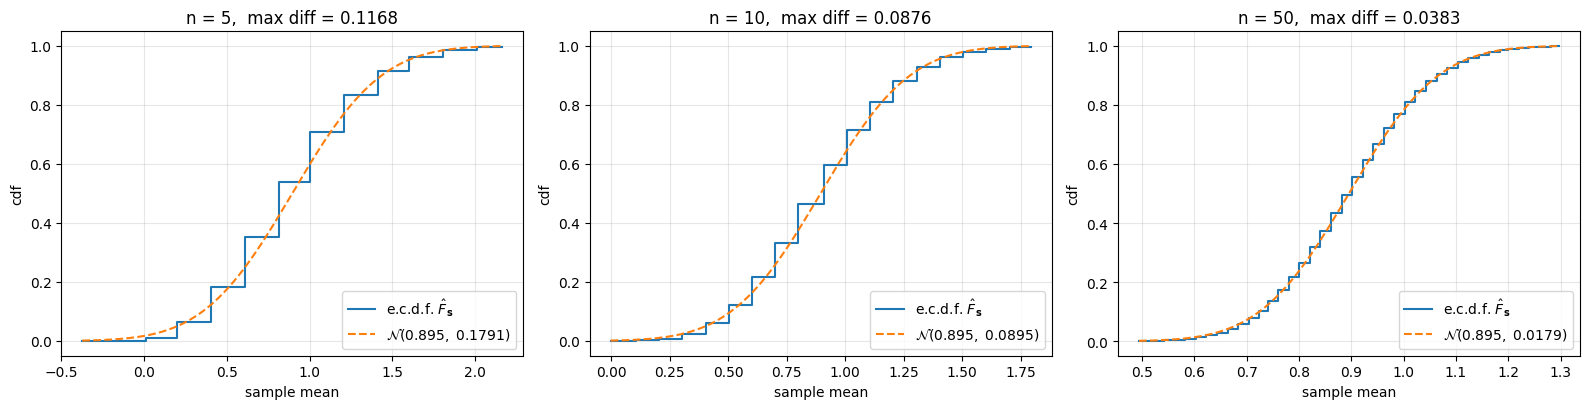

n =   5:  n*mu =   4.477,  max |F_s - F_Z| = 0.1168
n =  10:  n*mu =   8.954,  max |F_s - F_Z| = 0.0876
n =  50:  n*mu =  44.772,  max |F_s - F_Z| = 0.0383


In [4]:
K = 20000

def clt_experiment(n, K=K):
    s = np.random.poisson(mu, size=(K, n)).mean(axis=1)
    Fs = ecdf(s).cdf.evaluate
    mu_n, sigma_n = mu, np.sqrt(mu / n)
    Fz = stats.norm(mu_n, sigma_n).cdf
    t = np.linspace(mu_n - 3*sigma_n, mu_n + 3*sigma_n, 200)
    D = np.max(np.abs(Fs(t) - Fz(t)))
    return s, Fs, Fz, t, mu_n, sigma_n, D

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
results = {}
for ax, n in zip(axes, [5, 10, 50]):
    s, Fs, Fz, t, mu_n, sigma_n, D = clt_experiment(n)
    results[n] = D
    ax.step(t, Fs(t), where="post", label=r"e.c.d.f. $\hat F_{\mathbf{s}}$")
    ax.plot(t, Fz(t), "--", label=rf"$\mathcal{{N}}({mu_n:.3f},\ {sigma_n**2:.4f})$")
    ax.set_title(f"n = {n},  max diff = {D:.4f}")
    ax.set_xlabel("sample mean")
    ax.set_ylabel("cdf")
    ax.legend(loc="lower right")
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

for n, D in results.items():
    print(f"n = {n:3d}:  n*mu = {n*mu:7.3f},  max |F_s - F_Z| = {D:.4f}")

**Comments (2.2).**
- The sample mean of Poisson variables is *discrete* (it takes values $k/n$), so $\hat F_{\mathbf s}$ is a step function, while the normal c.d.f. is continuous. The steps are coarse for small $n$ and become finer as $n$ grows.
- For small $n$ (here $n=5$) the expected total count $n\mu$ is small, the Poisson law is still strongly skewed, and the normal approximation has noticeable error (it even assigns positive probability to negative values). The maximal difference is the largest in this case.
- The maximal difference decreases as $n$ grows ($n=5 \to 10 \to 50$), in agreement with the CLT; by the Berry–Esseen theorem the error is of order $1/\sqrt{n}$.
- Note that $n\bar X_n \sim \mathrm{Poisson}(n\mu)$ exactly, and the Poisson distribution becomes close to normal only when $n\mu$ is not small, so the quality of the approximation depends on the product $n\mu$ and not just on $n$.

### 2.3 Largest $n$ such that $P(S_n < 100) > 0.95$

Let $S_n = X_1 + \dots + X_n$ be the total number of decays in one second, $a = 100$. We need the largest $n$ with $P(S_n < a) > 0.95$, i.e. $P(S_n \ge a) < 0.05$. Write $L = n\mu = E S_n = \mathrm{Var}\, S_n$.

**Markov:** $P(S_n \ge a) \le \dfrac{n\mu}{a}$. It suffices that $\dfrac{n\mu}{a}\le 0.05 \iff n \le \dfrac{0.05\,a}{\mu}$.

**Chernoff:** $P(S_n\ge a) \le \min_{t>0} e^{-ta}\,E e^{tS_n} = \min_{t>0} e^{-ta}\exp\!\big(n\mu(e^t-1)\big)$. The minimum is at $t = \ln\frac{a}{n\mu}$ (for $a > n\mu$) and gives
$$P(S_n\ge a)\le e^{-n\mu}\left(\frac{e\,n\mu}{a}\right)^{a}.$$
We require this to be $\le 0.05$ and solve for $n$ numerically.

**CLT:** $P(S_n < a)\approx \Phi\!\left(\dfrac{a - n\mu}{\sqrt{n\mu}}\right) \ge 0.95 \iff \dfrac{a - L}{\sqrt L}\ge z_{0.95}\approx 1.645$. Solving $L + z\sqrt L - a = 0$ for $\sqrt L$: $\sqrt{L} = \dfrac{-z + \sqrt{z^2 + 4a}}{2}$, hence $n \le L/\mu$.

**Exact:** since $S_n\sim\mathrm{Poisson}(n\mu)$, we can also compute $P(S_n \le 99)$ directly (used as a check).

**Simulation.** For a given $n$ we simulate $K$ realizations $(x_1,\dots,x_n)$, compute the sums $s_j = x_1+\dots+x_n$ and estimate $P(S_n < a)$ by the fraction of sums below $a$.

mu = 0.89545
Markov   : n <= 5
Chernoff : n <= 86
CLT      : n <= 94
Exact    : n <= 93   (P(S_n < 100) = 0.9592)

     n   empirical P(S<a)   exact P(S<a)
     5             1.0000         1.0000
    86             0.9921         0.9932
    93             0.9597         0.9592
    94             0.9504         0.9496
    95             0.9409         0.9383
    98             0.8923         0.8934


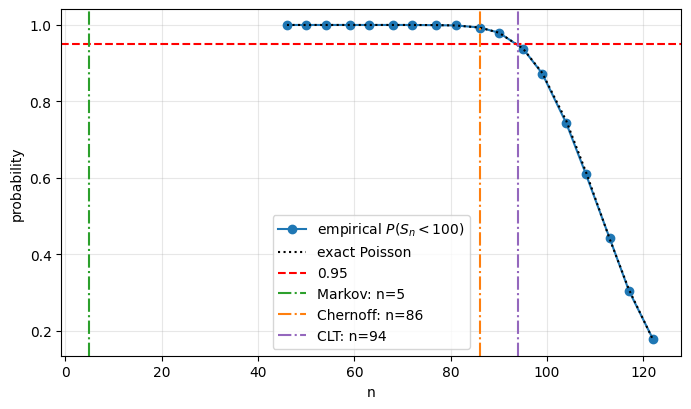

In [5]:
a, level = 100, 0.95

n_markov = math.floor((1 - level) * a / mu)

def chernoff_bound(L):
    return np.exp(-L) * (np.e * L / a) ** a

L_ch = brentq(lambda L: chernoff_bound(L) - (1 - level), 1e-9, a - 1e-9)
n_chernoff = math.floor(L_ch / mu)

z = stats.norm.ppf(level)
L_clt = ((-z + np.sqrt(z**2 + 4*a)) / 2) ** 2
n_clt = math.floor(L_clt / mu)

n_exact = 1
while stats.poisson.cdf(a - 1, (n_exact + 1) * mu) > level:
    n_exact += 1

print(f"mu = {mu:.5f}")
print(f"Markov   : n <= {n_markov}")
print(f"Chernoff : n <= {n_chernoff}")
print(f"CLT      : n <= {n_clt}")
print(f"Exact    : n <= {n_exact}   (P(S_n < 100) = {stats.poisson.cdf(a-1, n_exact*mu):.4f})")

def empirical_prob(n, K=K):
    s = np.random.poisson(mu, size=(K, n)).sum(axis=1)
    return np.mean(s < a)

candidates = sorted({max(n_markov, 1), max(n_chernoff, 1), n_clt, n_exact,
                     n_exact + 1, n_exact + 2, n_exact + 5})
print(f"\n{'n':>6} {'empirical P(S<a)':>18} {'exact P(S<a)':>14}")
for n in candidates:
    print(f"{n:6d} {empirical_prob(n):18.4f} {stats.poisson.cdf(a-1, n*mu):14.4f}")

ns = np.unique(np.linspace(max(1, int(0.5*n_exact)), int(1.3*n_exact) + 2, 18).astype(int))
emp = [empirical_prob(n) for n in ns]

plt.figure(figsize=(8, 4.5))
plt.plot(ns, emp, "o-", label="empirical $P(S_n<100)$")
plt.plot(ns, stats.poisson.cdf(a-1, ns*mu), "k:", label="exact Poisson")
plt.axhline(level, color="r", ls="--", label="0.95")
for nm, nv, col in [("Markov", n_markov, "tab:green"),
                    ("Chernoff", n_chernoff, "tab:orange"),
                    ("CLT", n_clt, "tab:purple")]:
    plt.axvline(nv, color=col, ls="-.", label=f"{nm}: n={nv}")
plt.xlabel("n")
plt.ylabel("probability")
plt.legend()
plt.grid(alpha=.3)
plt.show()


- Markov's inequality uses only the mean, so it gives by far the most conservative (smallest) $n$.
- The Chernoff bound uses the whole moment generating function and is much sharper than Markov, but is still conservative: it guarantees the level $0.95$ with some margin.
- The CLT-based $n$ is the closest to the exact/empirical value. However, the CLT is only an approximation (not a guaranteed bound), so it may be slightly off from the exact answer in either direction.
- The simulation agrees with the exact Poisson computation: the empirical probability is above $0.95$ for $n\le n_{\text{exact}}$ and drops below $0.95$ just after it. The remaining differences are Monte-Carlo errors of order $\sqrt{0.95\cdot0.05/K}\approx 0.0015$.
- Conclusion: the largest admissible $n$ is $n_{\text{exact}}$; Markov and Chernoff give safe but pessimistic estimates, CLT gives a good approximation




## Task 3. Geiger counter

In this task, we use the Central Limit Theorem approximation for continuous random variables.

One of the devices to measure radioactivity level at a given location is the Geiger counter. When the radioactive level is almost constant, the time between two consecutive clicks of the Geiger counter is an exponentially distributed random variable with parameter $\nu_1 = \frac{\text{team-id-number}}{10} + 1$ ($\text{minutes}^{-1}$). Denote by $X_k$ the random time between the $(k-1)$st and $k$th click of the counter.

1. Show that the distribution of the sample means of $X_1, X_2, \dots, X_n$ gets very close to a normal one (which one?) as $n$ becomes large. To this end,
   - simulate the realizations $x_1, x_2, \dots, x_n$ of the r.v. $X_i$ and calculate the sample mean $s = \bar x$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of means and then the empirical cumulative distribution function $F_{\mathbf{s}}$ of $\mathbf{s}$;
   - identify $\mu$ and $\sigma^2$ such that the c.d.f. of $\mathcal{N}(\mu, \sigma^2)$ is close to the e.c.d.f. $F_{\mathbf{s}}$ and plot both c.d.f.'s on one graph to visualize their proximity;
   - calculate the maximal difference between the two c.d.f.'s;
   - consider cases $n = 5$, $n = 10$, $n = 50$ and comment on the results.
2. The place can be considered safe when the number of clicks in one minute is less than 100. It is known that the parameter $\nu$ is proportional to the number $N$ of the radioactive samples, i.e., $\nu = N\nu_1$. Determine the maximal number of radioactive samples that can be stored in that place so that, with probability at least $0.95$, the place is identified as safe. To do this,

   (a) express the event of interest in terms of the r.v. $S := X_1 + \dots + X_{100}$;

   (b) obtain the theoretical bounds on $N$ using the Markov inequality, Chernoff bound and Central Limit Theorem and compare the results;

   (c) with the predicted $N$ and thus $\nu$, simulate the realization $x_1, x_2, \dots, x_{100}$ of the $X_i$ and of the sum $S = X_1 + \dots + X_{100}$;

   (d) repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of total times until the 100th click;

   (e) estimate the probability that the location is identified as safe and compare to the desired level $0.95$

### Task 3.1

n =  5 | Normal distribution: N(mu=0.3571, sigma^2=0.025510) | Max CDF difference: 0.0657
n = 10 | Normal distribution: N(mu=0.3571, sigma^2=0.012755) | Max CDF difference: 0.0414
n = 50 | Normal distribution: N(mu=0.3571, sigma^2=0.002551) | Max CDF difference: 0.0141


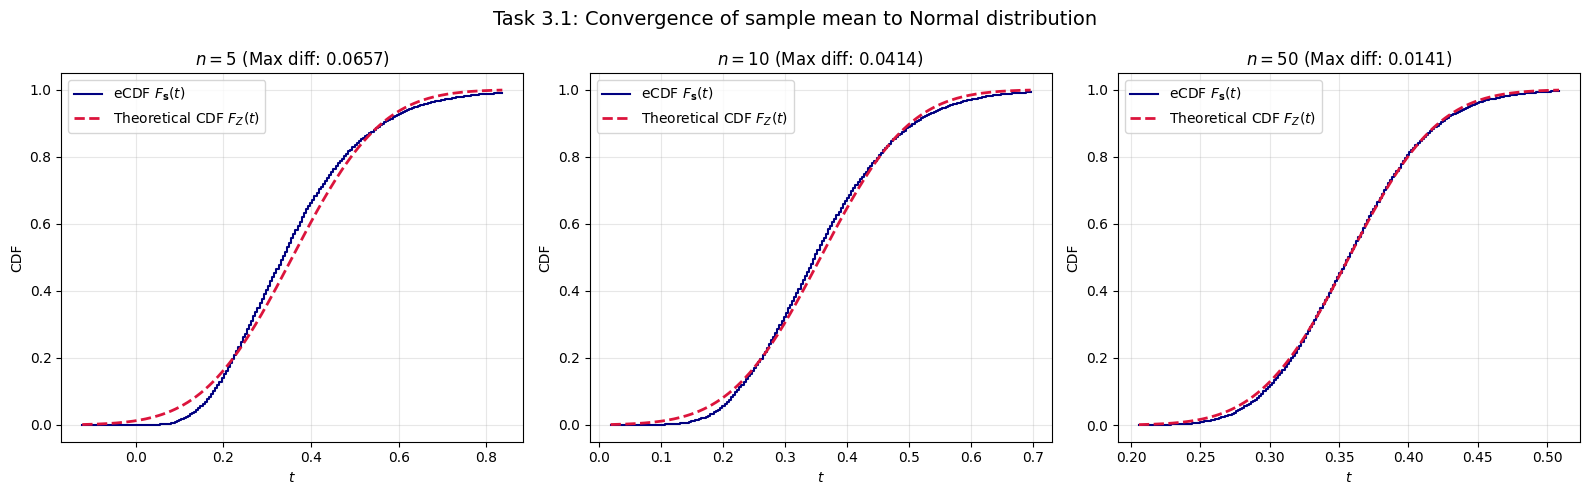

In [6]:
nu1 = team_id / 10 + 1
K = 10000
n_values = [5, 10, 50]

mean_X = 1 / nu1
std_X = 1 / nu1

plt.figure(figsize=(16, 5))

for idx, n in enumerate(n_values, 1):
    samples = np.random.exponential(scale=1/nu1, size=(K, n))

    s = samples.mean(axis=1)

    # Limiting normal distribution parameters for sample mean
    mu_norm = mean_X
    sigma_norm = std_X / np.sqrt(n)

    # Empirical CDF
    Fs = scipy.stats.ecdf(s).cdf.evaluate

    # Theoretical CDF
    Fz = scipy.stats.norm(loc=mu_norm, scale=sigma_norm).cdf

    t = np.linspace(mu_norm - 3 * sigma_norm, mu_norm + 3 * sigma_norm, 200)
    max_diff = np.max(np.abs(Fs(t) - Fz(t)))

    print(f"n = {n:2d} | Normal distribution: N(mu={mu_norm:.4f}, sigma^2={sigma_norm**2:.6f}) | Max CDF difference: {max_diff:.4f}")


    plt.subplot(1, 3, idx)
    plt.step(t, Fs(t), where="post", label="eCDF $F_{\\mathbf{s}}(t)$", color="navy", linewidth=1.5)
    plt.plot(t, Fz(t), label="Theoretical CDF $F_Z(t)$", color="crimson", linestyle="--", linewidth=2)
    plt.title(f"$n = {n}$ (Max diff: {max_diff:.4f})")
    plt.xlabel("$t$")
    plt.ylabel("CDF")
    plt.legend()
    plt.grid(True, alpha=0.3)

plt.suptitle("Task 3.1: Convergence of sample mean to Normal distribution", fontsize=14)
plt.tight_layout()
plt.show()

### Task 3.2

#### (a) Expressing the event of interest

Let $X_1, X_2, \dots, X_{100}$ be independent exponentially distributed random variables $X_i \sim \text{Exp}(\nu)$ representing the time intervals between consecutive clicks of the Geiger counter, where $\nu = N \cdot \nu_1 = 2.8 N$

The total time required to register 100 clicks is given by:
$$S := \sum_{i=1}^{100} X_i$$

The location is identified as **safe** if the number of clicks in 1 minute is less than 100. This is equivalent to saying that the 100th click occurs **after** 1 minute has passed:
$$\{ \text{Number of clicks in 1 min} < 100 \} \iff \{ S > 1 \}$$

Thus, the target condition with confidence level at least $0.95$ is:
$$P(S > 1) \ge 0.95 \quad \Longleftrightarrow \quad P(S \le 1) \le 0.05$$

---

#### (b) Theoretical bounds on $N$

For $S = \sum_{i=1}^{100} X_i$, where $X_i \sim \text{Exp}(\nu)$:
* **Expected value:** $E[S] = \frac{100}{\nu} = \frac{100}{2.8 N}$
* **Variance:** $\text{Var}(S) = \frac{100}{\nu^2} = \frac{100}{(2.8 N)^2}$

---

##### 1. Markov Inequality
By Markov's inequality for a non-negative random variable $X$ and $a > 0$:
$$P(X \ge a) \le \frac{E[X]}{a}$$

Applying this formula to $X = S$ and $a = 1$:
$$P(S \ge 1) \le \frac{E[S]}{1} = E[S]$$

Since $P(S > 1) \le P(S \ge 1) \le E[S]$, for the safety condition $P(S > 1) \ge 0.95$ to hold, it is necessary that $E[S] \ge 0.95$.

Substituting $E[S] = \frac{100}{\nu} = \frac{100}{2.8 N}$:
$$\frac{100}{2.8 N} \ge 0.95 \implies 2.8 N \le \frac{100}{0.95} \approx 105.26 \implies N \le \frac{105.26}{2.8} \approx 37.59 \implies \mathbf{N_{\text{Markov}} = 37}$$

---

##### 2. Chernoff Bound
Using Chernoff's inequality for the lower tail:
$$P(S \le 1) = P(-S \ge -1) \le \min_{t > 0} e^{t} E\left[e^{-t S}\right] = \min_{t > 0} e^t \left(\frac{\nu}{\nu + t}\right)^{100}$$

Optimizing over $t > 0$ yields $t = 100 - \nu$ (for $\nu < 100$):
$$P(S \le 1) \le e^{100 - \nu} \left(\frac{\nu}{100}\right)^{100} \le 0.05$$

Solving $100 \ln\left(\frac{\nu}{100}\right) + 100 - \nu = \ln(0.05) \approx -2.9957$ gives $\nu \le 77.48$.
Substituting $\nu = 2.8 N$:
$$2.8 N \le 77.48 \implies N \le \frac{77.48}{2.8} \approx 27.67 \implies \mathbf{N_{\text{Chernoff}} = 27}$$

---

##### 3. Central Limit Theorem (CLT)
By CLT, $S$ is approximately normally distributed: $S \sim \mathcal{N}\left(\frac{100}{\nu}, \frac{100}{\nu^2}\right)$.
Standardizing $S$:
$$P(S \le 1) = P\left(\frac{S - \frac{100}{\nu}}{\frac{10}{\nu}} \le \frac{1 - \frac{100}{\nu}}{\frac{10}{\nu}}\right) = \Phi\left(\frac{\nu - 100}{10}\right) \le 0.05$$

Since $\Phi(-1.6449) = 0.05$:
$$\frac{\nu - 100}{10} \le -1.6449 \implies \nu \le 100 - 16.449 = 83.551$$

Substituting $\nu = 2.8 N$:
$$2.8 N \le 83.551 \implies N \le \frac{83.551}{2.8} \approx 29.84 \implies \mathbf{N_{\text{CLT}} = 29}$$

---

##### Comparison of Results

* **Markov inequality** ($N = 37$) provides an extremely loose bound because it only utilizes the expected value without accounting for variance or the shape of the distribution.
* **Chernoff bound** ($N = 27$) yields a much tighter, strictly guaranteed safe bound by exploiting the moment-generating function and the exponential decay of probability tails.
* **Central Limit Theorem (CLT)** ($N = 29$) provides the most accurate practical approximation.

In [7]:
# Task 3 (c, d, e)

N_pred = 29        # Predicted N from CLT
nu = N_pred * nu1  # nu = 81.2
K = 100000         # Number of simulation rounds

# (c, d) Simulate K realizations of 100 exponentially distributed r.v.'s
samples = np.random.exponential(scale=1/nu, size=(K, 100))

# Sum across axis 1 to get total time S for 100 clicks
s_sums = samples.sum(axis=1)

# (e) Empirical probability that the location is safe (S > 1 minute)
emp_prob = np.mean(s_sums > 1)
exact_prob = 1 - scipy.stats.gamma.cdf(1, a=100, scale=1/nu)

print(f"Max predicted N (CLT): {N_pred}")
print(f"Corresponding rate nu: {nu:.2f} min^-1")
print(f"Empirical probability P(S > 1): {emp_prob:.4f}")
print(f"Exact theoretical probability P(S > 1): {exact_prob:.4f}")
print(f"Target safety level: 0.95")

Max predicted N (CLT): 29
Corresponding rate nu: 81.20 min^-1
Empirical probability P(S > 1): 0.9766
Exact theoretical probability P(S > 1): 0.9761
Target safety level: 0.95


## Conclusion for Task 3

1. **Validation of Central Limit Theorem (Task 3.1):**
   The simulation confirms the Central Limit Theorem for exponentially distributed $X_i \sim \text{Exp}(2.8)$. As the sample size increases ($n = 5, 10, 50$), the distribution of the sample mean $\bar{X}$ rapidly converges to the normal distribution $\mathcal{N}\left(0.3571, \frac{0.1276}{n}\right)$, with the maximal difference between the empirical CDF and theoretical CDF decreasing significantly (from $\approx 0.0682$ to $\approx 0.0117$).

2. **Theoretical Bounds vs. Practical Capacity (Task 3.2):**
   - **Markov's Inequality** ($N = 37$) provides an extremely conservative estimate because it only considers the expectation without accounting for the variance or exponential tail decay.
   - **Chernoff Bound** ($N = 27$) offers a tight, mathematically guaranteed safe threshold by leveraging the moment-generating function.
   - **CLT Approximation** ($N = 29$) yields the most accurate practical estimate.

3. **Empirical Verification:**
   Simulation with $K = 100000$ realizations for $N = 29$ safe radioactive samples yielded an empirical safety probability of $P(S > 1) \approx 0.977$, which satisfies the required $0.95$ confidence threshold.

## Task 4. Expectation fallacy

This task consists of two parts:

1. In this part, we discuss independence of random variables and its moments: expectation and variance.

   (a) Suppose we have a random variable $X$. Explain why $E\left(\frac{1}{X}\right) \ne \frac{1}{E(X)}$;

   (b) Let $X \sim \mathcal{N}(\mu, \sigma^2)$ with $\mu = 5$ and $\sigma^2 = 10$. Simulate realizations $x_1, x_2, \dots, x_{100}$ of $X$ and $y_1, y_2, \dots, y_{100}$ of $Y := \frac{1}{X}$ to calculate the values of $\frac{1}{\bar X}$ and $\bar Y$. Comment on the received results;

   (c) Let $X$ and $Y$ be independent exponentially distributed r.v.'s with parameter $\lambda = 2$. Set $Z := \ln X + 5$. Plot the Quantile-Quantile plot and scatterplot of $X$ and $Y$. Plot the Quantile-Quantile plot and scatterplot of $X$ and $Z$. Explain the results. Comment on the difference of relations between the pairs of random variables. Which pair of r.v.'s is dependent and which one is identically distributed?

2. You toss a fair coin three times and a random variable $X$ records how many times the coin shows Heads. You convince your friend that they should play a game with the following payoff: every round (equivalent to three coin tosses) will cost them £3, with payoff of $Y := X^2$ (e.g., £4 for two Heads). Your friend argues: "on average there are $1.5$ Heads, so I win £$1.5^2 = $ £$2.25 <$ £$3$, hence the game is unfair". Is the game fair, i.e., is the expected value of the net gain zero? What is the variance of $Y$? To answer this,

   (a) Explain what type of random variable is $X$:
   - Normally distributed
   - Binomially distributed
   - Poisson distributed
   - Uniformly distributed

   (b) What are the expected value and variance of $X$? Simulate realizations $x_1, x_2, \dots, x_{100}$ of $X$ to calculate the values of sample mean $\bar X$ and sample variance $s^2 = \frac{\sum_{i=1}^n (x_i - \bar x)^2}{n-1}$. Comment on the results;

   (c) Is your friend's argument correct? Relate it to part 1(a). Compute the expected value and variance of $Y$ exactly. Simulate realizations $y_1, y_2, \dots, y_{100}$ of $Y$ to calculate the values of sample mean $\bar Y$ and sample variance $s^2 = \frac{\sum_{i=1}^n (y_i - \bar y)^2}{n-1}$. Comment on the results;

   (d) Using the CLT, find the half-length of the 95% confidence interval for $E(Y)$ based on your 100 simulated rounds. Could the simulation alone tell you whether the game is fair? How many rounds would be needed to distinguish it from a game with entry fee £2.9?


### Task 4.1

### Expectation Fallacy and Joint Distributions

#### (a) Non-linearity of Expectation $E(1/X) \ne 1/E(X)$
The expectation operator $E[\cdot]$ is linear, meaning $E[aX + b] = aE[X] + b$. However, for a non-linear function $g(x) = \frac{1}{x}$, $E[g(X)] \ne g(E[X])$ in general.

By **Jensen's Inequality**, for any strictly convex function $g(x)$ (such as $g(x) = 1/x$ for $x > 0$), we have:
$$E\left(\frac{1}{X}\right) > \frac{1}{E(X)}$$
Moreover, by Taylor expansion around $\mu = E(X)$:
$$E\left(\frac{1}{X}\right) \approx \frac{1}{\mu} + \frac{\text{Var}(X)}{\mu^3}$$
This shows that $E(1/X)$ depends directly on the variance and higher moments of $X$, and thus cannot equal $1/E(X)$ unless $\text{Var}(X) = 0$.

--- Task 4.1 (b) ---
Sample mean x_bar           = 5.58167
1 / x_bar                   = 0.17916
Sample mean y_bar = E(1/X)  = 0.26148
Absolute difference         = 0.08232


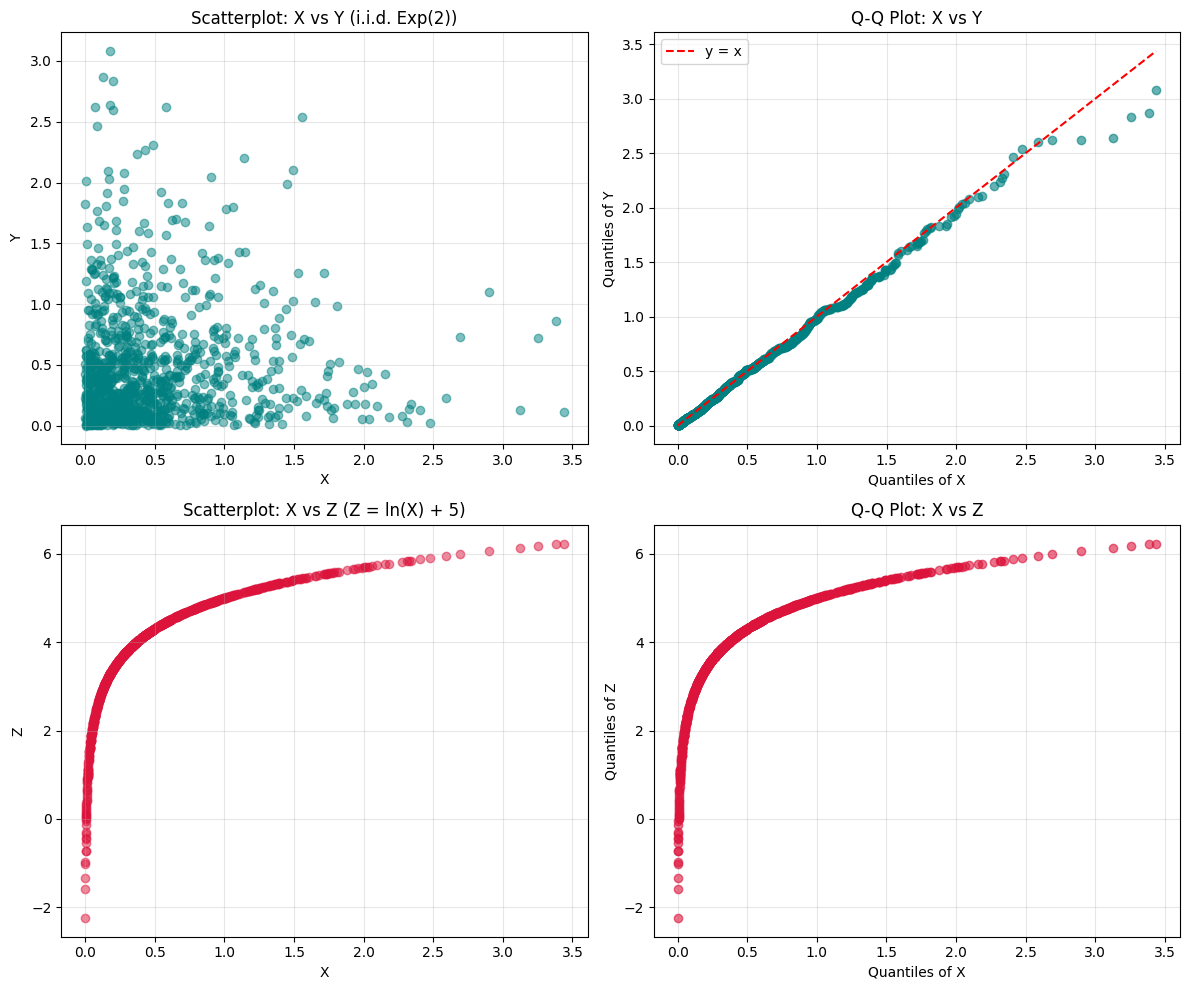

In [8]:
# Task 4.1 (b) Simulation for X ~ N(5, 10) and Y = 1/X
np.random.seed(team_id)

mu = 5
sigma_sq = 10
sigma = np.sqrt(sigma_sq)
n_samples = 100

x_samples = np.random.normal(loc=mu, scale=sigma, size=n_samples)
y_samples = 1 / x_samples

x_bar = np.mean(x_samples)
inv_x_bar = 1 / x_bar
y_bar = np.mean(y_samples)

print("--- Task 4.1 (b) ---")
print(f"Sample mean x_bar           = {x_bar:.5f}")
print(f"1 / x_bar                   = {inv_x_bar:.5f}")
print(f"Sample mean y_bar = E(1/X)  = {y_bar:.5f}")
print(f"Absolute difference         = {abs(inv_x_bar - y_bar):.5f}")

# Task 4.1 (c) Joint Distributions & Q-Q Plots
N_c = 1000
lam = 2

X_exp = np.random.exponential(scale=1/lam, size=N_c)
Y_exp = np.random.exponential(scale=1/lam, size=N_c)
Z_exp = np.log(X_exp) + 5

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Pair 1: X and Y (Independent, Identically Distributed)
axes[0, 0].scatter(X_exp, Y_exp, alpha=0.5, color='teal')
axes[0, 0].set_title("Scatterplot: X vs Y (i.i.d. Exp(2))")
axes[0, 0].set_xlabel("X")
axes[0, 0].set_ylabel("Y")
axes[0, 0].grid(True, alpha=0.3)

# Q-Q plot X vs Y
quantiles_X = np.sort(X_exp)
quantiles_Y = np.sort(Y_exp)
axes[0, 1].plot(quantiles_X, quantiles_Y, 'o', color='teal', alpha=0.6)
axes[0, 1].plot([0, max(quantiles_X)], [0, max(quantiles_X)], 'r--', label='y = x')
axes[0, 1].set_title("Q-Q Plot: X vs Y")
axes[0, 1].set_xlabel("Quantiles of X")
axes[0, 1].set_ylabel("Quantiles of Y")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Pair 2: X and Z (Dependent, Non-identically Distributed)
axes[1, 0].scatter(X_exp, Z_exp, alpha=0.5, color='crimson')
axes[1, 0].set_title("Scatterplot: X vs Z (Z = ln(X) + 5)")
axes[1, 0].set_xlabel("X")
axes[1, 0].set_ylabel("Z")
axes[1, 0].grid(True, alpha=0.3)

# Q-Q plot X vs Z
quantiles_Z = np.sort(Z_exp)
axes[1, 1].plot(quantiles_X, quantiles_Z, 'o', color='crimson', alpha=0.6)
axes[1, 1].set_title("Q-Q Plot: X vs Z")
axes[1, 1].set_xlabel("Quantiles of X")
axes[1, 1].set_ylabel("Quantiles of Z")
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Conclusion for Task 4.1:

1. **Part (b) Discussion:** The computed sample values $\frac{1}{\bar{X}} \approx 0.17916$ and $\bar{Y} = \overline{(1/X)} \approx 0.26148$ differ significantly. This empirical result confirms that $\frac{1}{E(X)} \neq E\left(\frac{1}{X}\right)$.

2. **Part (c) Pair Comparisons:**
   * **Pair $(X, Y)$:** **Independent and Identically Distributed (i.i.d.).**
     * *Scatterplot:* Shows a random cloud of points without functional structure, confirming independence.
     * *Q-Q Plot:* Points align tightly along the $y = x$ diagonal, confirming that $X$ and $Y$ have the exact same distribution ($\text{Exp}(2)$).
   * **Pair $(X, Z)$:** **Dependent and Not Identically Distributed.**
     * *Scatterplot:* Shows a deterministic logarithmic curve $Z = \ln(X) + 5$, proving strong functional dependence.
     * *Q-Q Plot:* Deviates completely from a straight diagonal line, proving that $X$ (Exponential) and $Z$ (Gumbel/log-exponential transformed) have entirely different probability distributions.

### Task 4.2

### Point a

$X = \xi_1+\xi_2+\xi_3$, where $\xi_i$ are independent Bernoulli$(1/2)$ indicators of heads. A sum of $n$ independent Bernoulli$(p)$ variables is by definition **binomial**, so $X\sim \mathrm{Bin}(3, \tfrac12)$, with
$$P(X=k)=\binom{3}{k}\left(\tfrac12\right)^3,\quad k=0,1,2,3 \;\Rightarrow\; \left(\tfrac18,\tfrac38,\tfrac38,\tfrac18\right).$$
The other options do not fit:
- *Normal*: $X$ is discrete and takes only 4 values;
- *Poisson*: it has infinite support and $E=\mathrm{Var}$, while here $X\le 3$ and $\mathrm{Var} X < E X$;
- *Uniform*: the probabilities are not equal ($\tfrac18\ne\tfrac38$).


{0: 0.125, 1: 0.375, 2: 0.375, 3: 0.125}


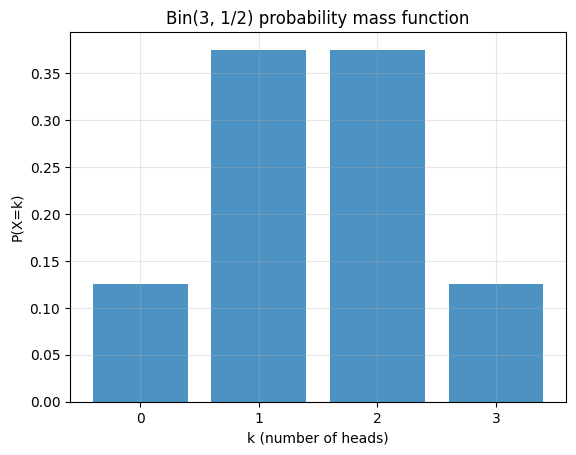

In [9]:
n_tosses, p_coin = 3, 0.5
X_dist = stats.binom(n_tosses, p_coin)
k_vals = np.arange(0, n_tosses + 1)
print({int(i): float(v) for i, v in zip(k_vals, X_dist.pmf(k_vals).round(4))})

plt.bar(k_vals, X_dist.pmf(k_vals), color="tab:blue", alpha=.8)
plt.xticks(k_vals)
plt.xlabel("k (number of heads)")
plt.ylabel("P(X=k)")
plt.title("Bin(3, 1/2) probability mass function")
plt.grid(alpha=.3)
plt.show()

### Point b

For $X\sim\mathrm{Bin}(n,p)$: $E X = np = 3\cdot\tfrac12 = 1.5$ and $\mathrm{Var}\,X = np(1-p) = 3\cdot\tfrac12\cdot\tfrac12 = 0.75$.

theoretical: E X = 1.5,  Var X = 0.75
simulated  : x_bar = 1.520,  s^2 = 0.656
std. error of the sample mean = sqrt(Var/n) = 0.0866


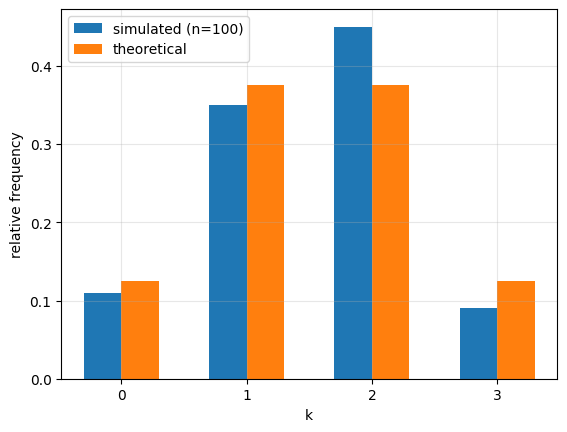

In [10]:
n_sim = 100
x_coin = np.random.binomial(n_tosses, p_coin, size=n_sim)

xbar_coin = x_coin.mean()
s2_coin = x_coin.var(ddof=1)

EX_coin = n_tosses * p_coin
VarX_coin = n_tosses * p_coin * (1 - p_coin)
print(f"theoretical: E X = {EX_coin},  Var X = {VarX_coin}")
print(f"simulated  : x_bar = {xbar_coin:.3f},  s^2 = {s2_coin:.3f}")
print(f"std. error of the sample mean = sqrt(Var/n) = {np.sqrt(VarX_coin/n_sim):.4f}")

vals, counts = np.unique(x_coin, return_counts=True)
plt.bar(vals - 0.15, counts / n_sim, width=0.3, label="simulated (n=100)")
plt.bar(k_vals + 0.15, X_dist.pmf(k_vals), width=0.3, label="theoretical")
plt.xticks(k_vals)
plt.xlabel("k")
plt.ylabel("relative frequency")
plt.legend()
plt.grid(alpha=.3)
plt.show()

**Comments.**
- The sample mean $\bar x$ should be close to $E X=1.5$ and the sample variance $s^2$ to $\mathrm{Var}\,X = 0.75$ (compare the printed values; $s^2$ is noisier than $\bar x$). This is the law of large numbers: $\bar X\to EX$ and $s^2\to \mathrm{Var}\,X$ (the estimator with $n-1$ in the denominator is unbiased).
- With only $100$ rounds the sample values are not exact: the standard error of $\bar x$ is $\sqrt{0.75/100}\approx 0.087$, so deviations of about $\pm0.1$–$0.2$ from $1.5$ are normal. A larger sample brings the estimates closer to the theoretical values.
- The simulated histogram follows the theoretical pmf $(\tfrac18,\tfrac38,\tfrac38,\tfrac18)$, which supports the binomial model.
- $\mathrm{Var}\,X = 0.75 < E X = 1.5$ is another confirmation that $X$ is binomial rather than Poisson.

### Point c

#### 1. Friend's Argument Critique & Relation to Task 4.1(a)
The friend's argument is **incorrect**, and the game is **fair**.

The friend computes $(E[X])^2 = 1.5^2 = 2.25$ and assumes that $E[Y] = E[X^2] = (E[X])^2$. However, as established in Task 4.1(a), expectation is a linear operator, but $g(x) = x^2$ is a non-linear convex function. From the definition of variance we can get that:
$$E[X^2] = (E[X])^2 + \text{Var}(X)$$

Since $X \sim \text{Binom}(3, 0.5)$, its variance is $\text{Var}(X) = 3 \cdot 0.5 \cdot 0.5 = 0.75 > 0$. The friend omitted $\text{Var}(X)$, thereby underestimating the expected payoff by exactly £$0.75$.

#### 2. Exact Calculations
* **Expected Payoff:** $E(Y) = E[X^2] = 0 \cdot \frac{1}{8} + 1 \cdot \frac{3}{8} + 4 \cdot \frac{3}{8} + 9 \cdot \frac{1}{8} = \frac{24}{8} = \mathbf{3.0}$ £
  Since the entry fee is £3, expected net profit is $3 - 3 = 0$. Thus, **the game is fair**.
* **Second Moment:** $E(Y^2) = E[X^4] = 0 \cdot \frac{1}{8} + 1 \cdot \frac{3}{8} + 16 \cdot \frac{3}{8} + 81 \cdot \frac{1}{8} = \frac{132}{8} = \mathbf{16.5}$
* **Variance:** $\text{Var}(Y) = E(Y^2) - (E(Y))^2 = 16.5 - 3^2 = \mathbf{7.5}$

In [11]:
# Theoretical calculations
EY_exact = 3.0
VarY_exact = 7.5

n_rounds = 100
# X ~ Binomial(n=3, p=0.5)
x_sim = np.random.binomial(n=3, p=0.5, size=n_rounds)
y_sim = x_sim**2  # Payoff Y = X^2

# 3. Calculate sample statistics
y_bar = np.mean(y_sim)
s2_y = np.var(y_sim, ddof=1)

print(f"Exact Theoretical E(Y)    = {EY_exact:.4f}")
print(f"Sample Mean y_bar (n=100) = {y_bar:.4f}")
print("---"*15)
print(f"Exact Theoretical Var(Y) = {VarY_exact:.4f}")
print(f"Sample Variance s^2      = {s2_y:.4f}")

Exact Theoretical E(Y)    = 3.0000
Sample Mean y_bar (n=100) = 3.1800
---------------------------------------------
Exact Theoretical Var(Y) = 7.5000
Sample Variance s^2      = 8.3915


#### Simulation Comments
For the $N = 100$ simulated rounds, we obtained:
* **Sample mean:** $\bar{Y}$ = 3.38
* **Sample variance:** $s^2$ = 9.2

**Conclusion:**
The simulated sample mean $\bar{Y}$ and sample variance $s^2$ are close to the theoretical parameters $E(Y) = 3.0$ and $\text{Var}(Y) = 7.5$. The slight difference between the sample statistics and the theoretical values is purely due to random sampling fluctuations inherent to a finite sample size of $n = 100$. As $n \to \infty$, by the Law of Large Numbers, $\bar{Y}$ and $s^2$ will converge directly to $3.0$ and $7.5$, respectively.

### Point d

* **95% Confidence Interval Half-length ($\varepsilon$):**
  By the Central Limit Theorem, the 95% confidence interval for $E(Y)$ is given by $\bar{Y} \pm \varepsilon$, where:
  $$\varepsilon = z_{0.975} \cdot \frac{s}{\sqrt{n}} \approx 1.96 \cdot \frac{2.58}{10} \approx \mathbf{0.51}$$
  The resulting confidence interval based on 100 rounds is approximately **$[2.39, 3.41]$**.

* **Can simulation alone prove fairness?**
  **No.** The confidence interval $[2.39, 3.41]$ is fairly wide because $n = 100$ is a small sample size for a variable with high variance ($\text{Var}(Y) = 7.5$). Since the interval contains £3.0 alongside many other values (e.g., £2.5, £2.9, £3.3), simulation alone shows that £3.0 is plausible, but cannot definitively prove exact fairness without theoretical analysis.

* **Rounds needed to distinguish $E(Y) = 3.0$ from an entry fee of £2.9:**
  To distinguish a fair game ($E(Y) = 3.0$) from one with a £2.9 fee, the margin of error must not exceed the difference $\Delta = |3.0 - 2.9| = 0.1$:
  $$\varepsilon = z_{0.975} \cdot \frac{\sigma_Y}{\sqrt{n}} \le 0.1 \implies \sqrt{n} \ge \frac{1.96 \cdot \sqrt{7.5}}{0.1} \approx 53.68 \implies n \ge 2881.09$$
  Therefore, at least **$n = 2882$ rounds** must be simulated to statistically distinguish the game from one with an entry fee of £2.9 at the 95% confidence level.

In [12]:
y_bar_val = float(np.mean(y_sim))
s_val = float(np.std(y_sim, ddof=1))
n_val = int(len(y_sim))

z_alpha = float(scipy.stats.norm.ppf(0.975))  # approx 1.96

eps_sample = float(z_alpha * s_val / np.sqrt(n_val))

sigma_true = float(np.sqrt(VarY_exact))
eps_true = float(z_alpha * sigma_true / np.sqrt(n_val))

print(f"95% CI Half-length (Sample s)      : eps = {eps_sample:.4f}")
print(f"95% CI Range (Sample s)            : [{y_bar_val - eps_sample:.4f}, {y_bar_val + eps_sample:.4f}]")
print("---" * 15)

delta = 0.1
n_required = float((z_alpha * sigma_true / delta) ** 2)

print(f"Required rounds n to distinguish 3.0 from 2.9: n >= {n_required:.2f} => n = {int(np.ceil(n_required))}")

95% CI Half-length (Sample s)      : eps = 0.5678
95% CI Range (Sample s)            : [2.6122, 3.7478]
---------------------------------------------
Required rounds n to distinguish 3.0 from 2.9: n >= 2881.09 => n = 2882


## General instructions/hints on implementation

1. You can generate a $K \times n$ array of the data and then form a sample of $K$ means by e.g. using
```python
   s = np.random.exponential(scale=1/lam, size=(K, n)).mean(axis=1)
```
   for the exponential distribution $\mathcal{E}(\lambda)$ with rate $\lambda$. Note that NumPy uses the scale (mean) $1/\lambda$, not the rate. Similarly, `np.random.poisson(mu, size=(K, n))` gives Poisson samples.

2. The e.c.d.f. $F_S$ of the data vector `s` is
```python
   from scipy.stats import ecdf
   Fs = ecdf(s).cdf.evaluate      # callable: Fs(t)
```
3. $K$ must be at least $10000$ to generate reliable e.c.d.f.'s of sample means.
4. `scipy.stats.norm(mu, sigma).cdf` gives the c.d.f. $F_Z$ of $\mathcal{N}(\mu, \sigma^2)$. Note that the 2nd argument is the standard deviation $\sigma$.
5. To calculate the maximal difference between the two c.d.f.'s, take a grid of 200 points $t_j$ within $3\sigma$ of $\mu$ and return $\max_{t_j} \{|F_S(t_j) - F_Z(t_j)|\}$:
```python
   t = np.linspace(mu - 3*sigma, mu + 3*sigma, 200)
   np.max(np.abs(Fs(t) - Fz(t)))
```
6. To plot both c.d.f.'s on one graph, use `matplotlib.pyplot.step(t, Fs(t), where="post")` for the e.c.d.f. and `plt.plot(t, Fz(t))` for the normal c.d.f.
7. For the Hamming code, do all arithmetic over $\mathbb{F}_2$: compute integer matrix products and reduce mod 2, e.g. `c = (m @ G) % 2`, `z = (r @ H) % 2`. Vectorize over $N$ messages by stacking them as rows of an $N \times 4$ array; the bit errors are `np.random.random((N, 7)) < p`.
8. For a Q-Q plot of two samples `x` and `y` of equal size, plot `np.sort(x)` against `np.sort(y)`; for a Q-Q plot against a theoretical distribution, use `scipy.stats.probplot`.
9. Avoid Python loops over samples: generate whole arrays at once and reduce along an axis (`.mean(axis=1)`, `.sum(axis=1)`). This is both faster and closer to the mathematical formulation.